In [ ]:
import torch;
print(torch.cuda.is_available())

In [31]:
#NB: Kaggle requires phone verification to use the internet or a GPU. If you haven't done that yet, the cell below will fail
#    This code is only here to check that your internet is enabled. It doesn't do anything else.
#    Here's a help thread on getting your phone number verified: https://www.kaggle.com/product-feedback/135367

import socket,warnings
try:
    socket.setdefaulttimeout(1)
    socket.socket(socket.AF_INET, socket.SOCK_STREAM).connect(('1.1.1.1', 53))
except socket.error as ex: raise Exception("STOP: No internet. Click '>|' in top right and set 'Internet' switch to on")

In [33]:
%pip install ddgs

   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   -------------------------- ------------- 2.6/4.0 MB 15.1 MB/s eta 0:00:01
   ---------------------------------------- 4.0/4.0 MB 17.2 MB/s  0:00:00
   ---------------------------------------- 0.0/6.4 MB ? eta -:--:--
   -------------- ------------------------- 2.4/6.4 MB 16.8 MB/s eta 0:00:01
   ---------------------------------- ----- 5.5/6.4 MB 12.4 MB/s eta 0:00:01
   ---------------------------------------- 6.4/6.4 MB 12.6 MB/s  0:00:00

   ------------- -------------------------- 1/3 [lxml]
   ------------- -------------------------- 1/3 [lxml]
   -------------------------- ------------- 2/3 [ddgs]
   -------------------------- ------------- 2/3 [ddgs]
   ---------------------------------------- 3/3 [ddgs]

Note: you may need to restart the kernel to use updated packages.


In [34]:
from fastcore.all import *
from ddgs import DDGS

def search_images(keywords, max_images=200):
    with DDGS() as d:
        return L(d.images(keywords, max_results=max_images)).itemgot('image')

In [42]:
#NB: `search_images` depends on duckduckgo.com, which doesn't always return correct responses.
#    If you get a JSON error, just try running it again (it may take a couple of tries).
urls = search_images('birds photos', max_images=1)
urls[0]

'https://images.pexels.com/photos/326900/pexels-photo-326900.jpeg?cs=srgb&dl=pexels-pixabay-326900.jpg&fm=jpg'

C:\dev\python\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


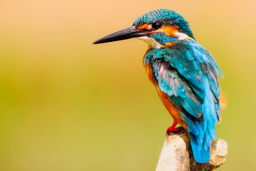

In [49]:
from fastdownload import download_url
dest = 'bird.jpg'
download_url(urls[0], dest, show_progress=False)

from fastai.vision.all import *
im = Image.open(dest)
im.to_thumb(256,256)

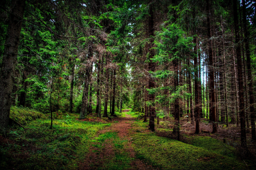

In [51]:
download_url(search_images('forest photos', max_images=1)[0], 'forest.jpg', show_progress=False)
Image.open('forest.jpg').to_thumb(256,256)

In [52]:
searches = 'forest','bird'
path = Path('bird_or_not')

for o in searches:
    dest = (path/o)
    dest.mkdir(exist_ok=True, parents=True)
    download_images(dest, urls=search_images(f'{o} photo'))
    time.sleep(5)
    resize_images(path/o, max_size=400, dest=path/o)

In [54]:
failed = verify_images(get_image_files(path))
failed.map(Path.unlink)
len(failed)

0

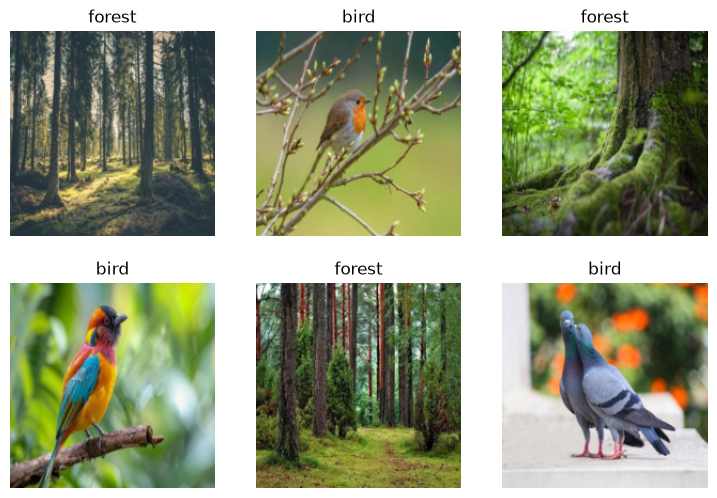

In [55]:
dls = DataBlock(
    blocks=(ImageBlock, CategoryBlock), 
    get_items=get_image_files, 
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=[Resize(192, method='squish')]
).dataloaders(path, bs=32)

dls.show_batch(max_n=6)

In [56]:
learn = vision_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(3)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\lukas/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:03<00:00, 12.2MB/s]


epoch,train_loss,valid_loss,error_rate,time
0,1.974195,1.423323,0.615385,00:01


epoch,train_loss,valid_loss,error_rate,time
0,1.022254,0.981451,0.538462,00:00
1,1.021421,0.434703,0.384615,00:00
2,0.735261,0.201921,0.153846,00:00


In [57]:
is_bird,_,probs = learn.predict(PILImage.create('bird.jpg'))
print(f"This is a: {is_bird}.")
print(f"Probability it's a bird: {probs[0]:.4f}")

This is a: bird.
Probability it's a bird: 1.0000


In [58]:
git --version

NameError: name 'git' is not defined